# Phys 434 Final Project: RFI Identification

In [7]:
# pip install pyuvdata
# pip install pooch
# pip install hera_pspec

In [174]:
%matplotlib inline
# standard imports
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import numpy.ma
from scipy import interpolate
import warnings
from astropy.time import Time
warnings.filterwarnings('ignore', module='hera_sim')
warnings.filterwarnings('ignore', category=RuntimeWarning)

# HERA-Stack
# import hera_pspec as hp

# PyUVData
from pyuvdata import UVData
from pyuvdata.datasets import fetch_data

## Statistical Question:

### What is the likely-hood that the radio background(to be identified) produces values much greater than the mean?

The goal here is to identify the radio background distribtution, calculate the sigma value, and then filter out data points that exist multiple sigma from the mean as RFI.

In [34]:
# Read in the data
uvd = UVData()
uvd.read_uvh5(filename = 'zen.2459122.34011.mini.sum.uvh5')
data = uvd.data_array

In [153]:
uvd.get_data(1,2)

array([[210106.-275166.j, 205484.-280434.j, 206517.-288772.j, ...,
         18191. +13982.j,  10302. +14090.j,   2152. +34580.j],
       [206056.-275371.j, 203737.-282078.j, 202926.-288805.j, ...,
         20045. +15598.j,  14470. +12758.j,   6313. +32015.j],
       [206578.-276794.j, 206660.-281759.j, 211574.-288184.j, ...,
         14010. +16270.j,   9256. +20741.j,  10860. +35515.j],
       ...,
       [205650.-289909.j, 199909.-296852.j, 196118.-302192.j, ...,
         12830. +10998.j,   1032. +14851.j,  -4038. +26277.j],
       [199249.-291569.j, 194889.-299638.j, 196879.-304035.j, ...,
         10573. +15327.j,    401. +11453.j,  -4778. +26915.j],
       [202337.-291668.j, 198970.-298190.j, 198033.-303530.j, ...,
          8947. +16936.j,    961.  +7366.j,  -2081. +22466.j]],
      shape=(20, 1536))

In [200]:
# Format it as a waterfall plot

# This gathers the data for just the antenna pair 1,2 in one polarization
waterfall_data = uvd.get_data((1, 2))

mean_data = np.mean(waterfall_data, axis = 0)

# This gets the times associated with the baseline
waterfall_times = Time(uvd.get_times((1, 2, uvd.polarization_array[0])), format="jd").iso


In [155]:
# Find the mean data value and standard deviation for the antenna pair
mean_val = np.mean(np.abs(waterfall_data))
std_val = np.std(np.abs(waterfall_data))

(300.0, 500.0)

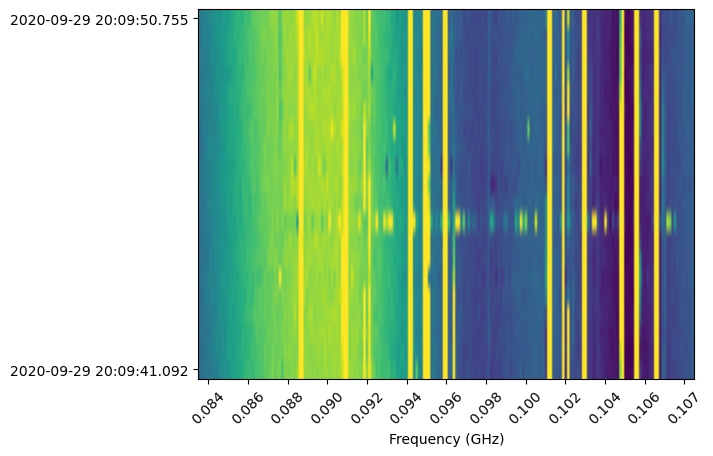

In [156]:
# Plot the waterfall with frequency vs time, color scale is intensity
fig, ax = plt.subplots()
ax.imshow(np.abs(waterfall_data), origin = 'lower', interpolation = None, vmax = mean_val )
ax.set_aspect('auto')
ax.set_yticks([0, waterfall_times.size - 1])
ax.set_yticklabels([waterfall_times[0], waterfall_times[1]])

freq_tick_inds = np.concatenate((np.arange(0, uvd.Nfreqs, 16), [uvd.Nfreqs-1]))
ax.set_xticks(freq_tick_inds)
ax.set_xticklabels([f"{val:.3f}" for val in uvd.freq_array[freq_tick_inds]*1e-9])
ax.tick_params(axis='x', labelrotation=45)
ax.set_xlabel("Frequency (GHz)")

ax.set_xlim(300,500)

### Looking at time averaged data for the antenna pair

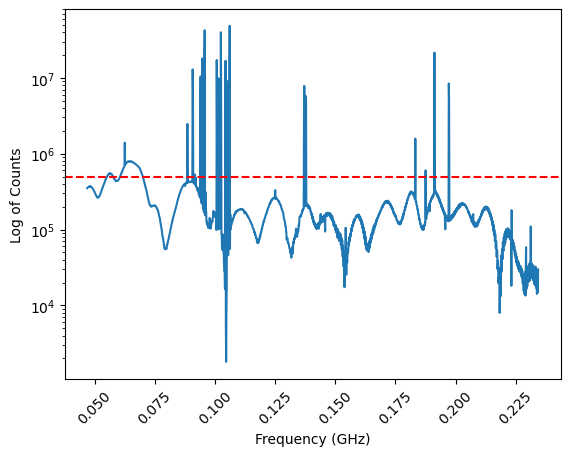

In [203]:
# Plot of the counts vs frequency for one timestep in logspace

freqs = uvd.freq_array*1e-9
fig, ax = plt.subplots()
ax.plot(freqs, np.abs(mean_data))
ax.axhline(mean_val, color = 'red', linestyle = '--')

# freq_tick_inds = np.concatenate((np.arange(0, uvd.Nfreqs, 128), [uvd.Nfreqs-1]))
# ax.set_xticks(freq_tick_inds)
# ax.set_xticklabels([f"{val:.3f}" for val in uvd.freq_array[freq_tick_inds]*1e-9])
ax.tick_params(axis='x', labelrotation=45)
ax.set_xlabel("Frequency (GHz)")
ax.set_ylabel("Log of Counts")
# ax.set_ylim(0,1e7)
ax.set_yscale('log')

In [222]:
# Filter out data points below the mean to try and quantify a background distribution
avg_counts = np.mean(np.abs(mean_data))

(0.0, 1000000.0)

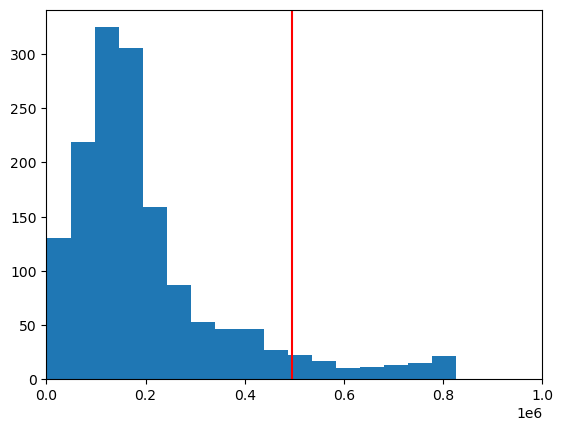

In [225]:
fig, ax = plt.subplots()

ax.hist(np.abs(mean_data), bins = 1000)
ax.axvline(mean_val, color = 'red')
ax.set_xlim(0,0.1e7)

### Plan for removal:

- Identify background dist through a fit
- Calculate the sigma threshold
- Remove the outlier data
- Perform same calculation for each antenna pair
- Apply to the MWA data as well

**Below here is data for all baselines**
___
I think it will be better to do the above on a case by case basis instead of look at all baselines at once

In [160]:
# Gets the data for all the baselines in the single polarization
data_bls = uvd.get_data(uvd.polarization_array[0])

(300.0, 500.0)

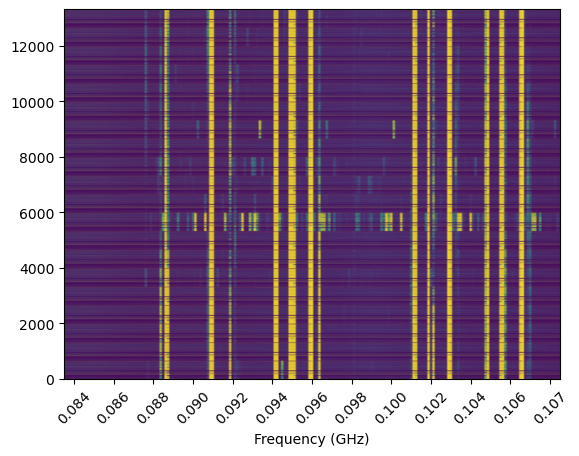

In [157]:
# This is the waterfall plot taken across all of the baselines/antenna pairs instead of just 1
fig, ax = plt.subplots()
ax.imshow(np.abs(data_bls), origin = 'lower', interpolation = None, vmax = mean_val )
ax.set_aspect('auto')

freq_tick_inds = np.concatenate((np.arange(0, uvd.Nfreqs, 16), [uvd.Nfreqs-1]))
ax.set_xticks(freq_tick_inds)
ax.set_xticklabels([f"{val:.3f}" for val in uvd.freq_array[freq_tick_inds]*1e-9])
ax.tick_params(axis='x', labelrotation=45)
ax.set_xlabel("Frequency (GHz)")

ax.set_xlim(300,500)

In [168]:
flags = uvd.flag_array

array([[False],
       [False],
       [False],
       ...,
       [False],
       [False],
       [False]], shape=(1536, 1))

In [169]:
# This algorithm check if there are any flagged values in the dataset already
# For this dataset there are none
for i in range(0, len(flags)):
    
    check = any(flags[i])
    flag_count = 0
    if check == True:
        flag_count += 1

print(flag_count)

0


In [186]:
data = np.abs(data_bls)
data = data[data > 0]

In [194]:
mean_amp = np.mean(data)

Text(0, 0.5, 'Counts')

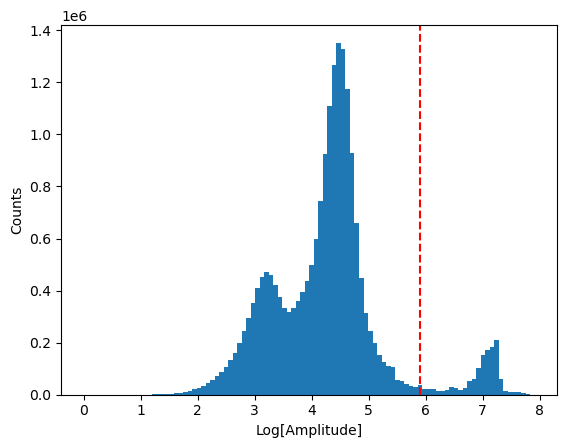

In [215]:
# Log plot of all baselines, from Elias, not 100% sure how to quantify
fig, ax = plt.subplots()
ax.hist(np.log10(data), bins = 100);
ax.axvline(np.log10(mean_amp), color = 'red', linestyle = '--')
ax.set_xlabel('Log[Amplitude]')
ax.set_ylabel('Counts')